Apply the trained model on the actual testset.

In [ ]:
import json
import sys

import numpy as np
import torch

from afrans.config import SURFACE, TARGETS
from afrans.config import CACHE_DIR, CKPT_DIR, REPO_ROOT, TARGET_NAMES, GridConfig, TrainConfig
sys.path.append(str(REPO_ROOT / "scripts"))
from evaluate import load_full_sim, predict_sim

from afrans.engine import resolve_device
from afrans.graph_dataset import build_graph
from afrans.metrics import relative_l2, summarize
from afrans.models.fno import build_fno
from afrans.models.gnn import build_gnn
from afrans.normalise import Normaliser
from afrans.splits import simulation_names

In [2]:
test_names = simulation_names("full", train=False)
print(f"{len(test_names)} held-out test simulations")

norm = Normaliser(); norm.load(CACHE_DIR / "normaliser.npz")

200 held-out test simulations


In [3]:
fno_ckpt_path = CKPT_DIR / (TrainConfig(loss_weighting="density").run_name(GridConfig()) + ".pt")
fno_ck = torch.load(fno_ckpt_path, map_location="cpu", weights_only=False)
fno_train_cfg = TrainConfig(**fno_ck["train_cfg"])
fno_grid_cfg = GridConfig(**fno_ck["grid_cfg"])
fno_model = build_fno(fno_train_cfg); fno_model.load_state_dict(fno_ck["model"]); fno_model.eval()

gnn_ckpt_path = CKPT_DIR / (TrainConfig(model="gnn").run_name() + ".pt")
gnn_ck = torch.load(gnn_ckpt_path, map_location="cpu", weights_only=False)
gnn_train_cfg = TrainConfig(**gnn_ck["train_cfg"])
gnn_model = build_gnn(gnn_train_cfg); gnn_model.load_state_dict(gnn_ck["model"]); gnn_model.eval()


GNN(
  (convs): ModuleList(
    (0): SAGEConv(7, 32, aggr=mean)
    (1-2): 2 x SAGEConv(32, 32, aggr=mean)
    (3): SAGEConv(32, 4, aggr=mean)
  )
)

In [ ]:
def evaluate_fno(names):
    all_errs, surf_errs = [], []
    for name in names:
        sim = load_full_sim(name)
        y_true = sim[:, TARGETS]
        surf = sim[:, SURFACE] > 0.5
        y_pred = predict_sim(fno_model, norm, fno_grid_cfg, torch.device("cpu"), sim)
        all_errs.append(relative_l2(y_pred, y_true))
        surf_errs.append(relative_l2(y_pred, y_true, mask=surf,
                                     ref_norm=norm.target_std * np.sqrt(surf.sum())))
    return summarize(all_errs, TARGET_NAMES), summarize(surf_errs, TARGET_NAMES)

def evaluate_gnn(names):
    all_errs, surf_errs = [], []
    for name in names:
        sim = load_full_sim(name)
        y_true = sim[:, TARGETS]
        data = build_graph(name, norm, k=gnn_train_cfg.k_neighbors)
        with torch.no_grad():
            pred_norm = gnn_model(data.x, data.edge_index)
        y_pred = norm.inverse_target(pred_norm.numpy())
        surf = data.surface.numpy()
        all_errs.append(relative_l2(y_pred, y_true))
        surf_errs.append(relative_l2(y_pred, y_true, mask=surf,
                                     ref_norm=norm.target_std * np.sqrt(surf.sum())))
    return summarize(all_errs, TARGET_NAMES), summarize(surf_errs, TARGET_NAMES)

In [4]:
fno_all, fno_surf = evaluate_fno(test_names)
gnn_all, gnn_surf = evaluate_gnn(test_names)

In [5]:
print(f"{'target':10s} {'FNO all':>9s} {'GNN all':>9s} {'FNO surf':>9s} {'GNN surf':>9s}")
for name in TARGET_NAMES:
    print(f"{name:10s} {fno_all[name]['mean']:8.1%} {gnn_all[name]['mean']:8.1%} "
          f"{fno_surf[name]['mean']:8.1%} {gnn_surf[name]['mean']:8.1%}")

results_test = {
    "n_test_sims": len(test_names),
    "fno": {"all_points": fno_all, "surface_points": fno_surf},
    "gnn": {"all_points": gnn_all, "surface_points": gnn_surf},
}
(REPO_ROOT / "results_test.json").write_text(json.dumps(results_test, indent=2))

target       FNO all   GNN all  FNO surf  GNN surf
vx            36.8%    22.1%   115.5%    19.0%
vy            60.2%    37.9%    66.7%    19.4%
pressure      85.1%    56.7%    80.5%    53.7%
nu_t          61.1%    49.5%    53.6%    19.4%


1699

/opt/homebrew/Caskroom/miniconda/base/envs/airfrans/lib/python3.9/site-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))
/opt/homebrew/Caskroom/miniconda/base/envs/airfrans/lib/python3.9/site-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/opt/homebrew/Caskroom/miniconda/base/envs/airfrans/lib/python3.9/site-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/opt/homebrew/Caskroom/miniconda/base/envs/airfrans/lib/python3.9/site-packages/matplotlib/_mathtext.py:45: PyparsingDeprecationWarning: 'enablePackrat' deprecated - use 'enable_packrat'
  ParserElement.enablePackrat()
In /opt/homebrew/Caskroom/miniconda/base/envs/airfrans/lib/python3.9/sit

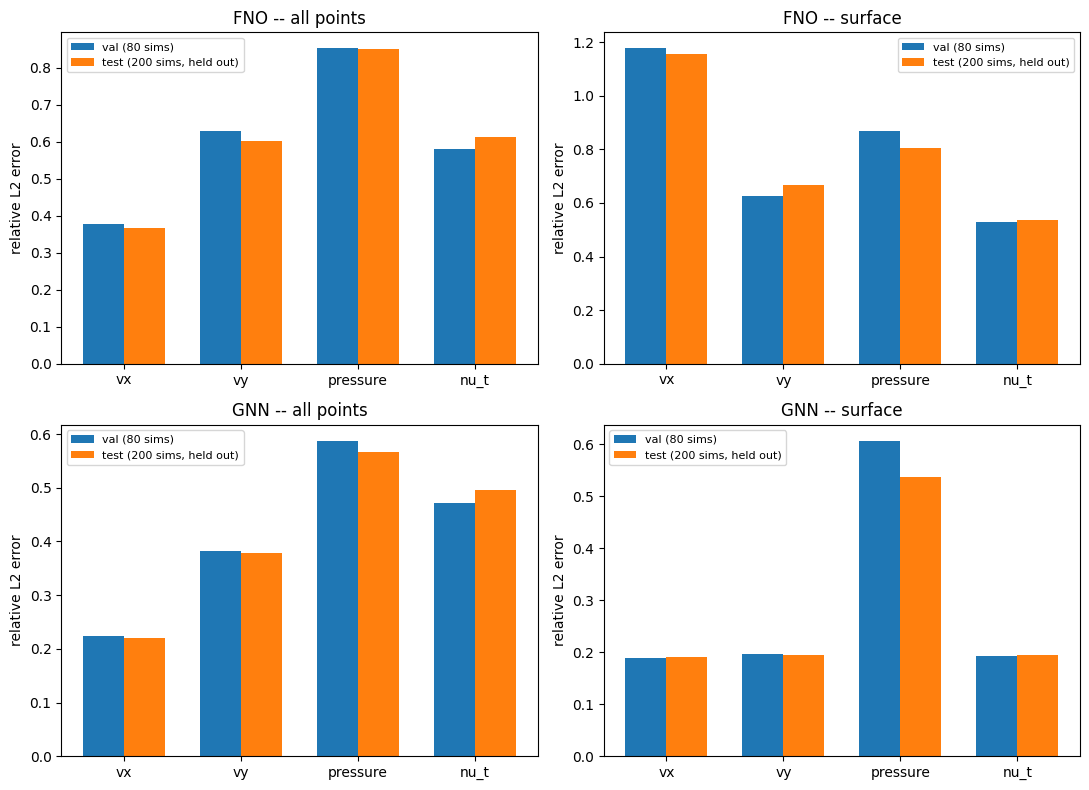

In [6]:
import matplotlib.pyplot as plt
import numpy as np

fno_val = json.loads((REPO_ROOT / "results.json").read_text())
gnn_val = json.loads((REPO_ROOT / "results_gnn.json").read_text())

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=False)
x = np.arange(len(TARGET_NAMES))
width = 0.35

panels = [
    (axes[0, 0], fno_val["all_points"], fno_all, "FNO -- all points"),
    (axes[0, 1], fno_val["surface_points"], fno_surf, "FNO -- surface"),
    (axes[1, 0], gnn_val["all_points"], gnn_all, "GNN -- all points"),
    (axes[1, 1], gnn_val["surface_points"], gnn_surf, "GNN -- surface"),
]
for ax, val_dict, test_dict, title in panels:
    val_means = [val_dict[n]["mean"] for n in TARGET_NAMES]
    test_means = [test_dict[n]["mean"] for n in TARGET_NAMES]
    ax.bar(x - width/2, val_means, width, label="val (80 sims)")
    ax.bar(x + width/2, test_means, width, label="test (200 sims, held out)")
    ax.set_xticks(x); ax.set_xticklabels(TARGET_NAMES)
    ax.set_title(title)
    ax.set_ylabel("relative L2 error")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


The results show that the mean error of testsets are generally aligned with the validation set, which means the models are not overfited.